# IIA 2026 - TP2 - Árboles de Decisión

### Santiago Bussanich, Gaspar Giménez, Valentín Sosa

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from typing import Tuple
from sklearn.decomposition import PCA
import ipywidgets as widgets
from IPython.display import display
from ipywidgets import interact, IntSlider

In [ ]:
def diagonales(d: int, C: float, n: int) -> Tuple[np.ndarray, np.ndarray]:
    """
    Genera sampleos de dos gausianas d-dimensionales en posición diagonal
    (una respecto a la otra), con dispersión C * sqrt(d).
    Cada sampleo posee n/2 puntos.

    Argumentos:
        d: número de dimensiones
        C: constante de ajuste de dispersión
        n: número de ejemplos a generar

    Retorna:
        X: matriz con d columnas y n filas de datos
        y: arreglo de n elementos con las clases correspondientes
            a cada fila de datos
    """
    std = C * np.sqrt(d)
    cov = np.diag(np.full(d, std**2))

    X, y = np.array([]), np.array([])

    mean_1 = np.ones(d)
    mean_0 = -np.ones(d)

    half = n // 2

    X_1 = np.random.multivariate_normal(mean_1, cov, half)
    X_0 = np.random.multivariate_normal(mean_0, cov, half)

    X = np.vstack([X_0, X_1])
    y = np.hstack([np.zeros(half), np.ones(half)])

    return X, y

In [ ]:
diag_X, diag_y = diagonales(2, 0.5, 10000)

In [ ]:
def paralelas(d: int, C: float, n: int) -> Tuple[np.ndarray, np.ndarray]:

  X, y = np.array([]), np.array([])

  mean_1 = np.full(d,0)
  mean_1[0] = 1

  mean_0 = np.full(d,0)
  mean_0[0] = -1

  half = n // 2

  X_1 = np.random.multivariate_normal(mean_1, (C**2)*np.eye(d), half)
  X_0 = np.random.multivariate_normal(mean_0, (C**2)*np.eye(d), half)

  X = np.vstack([X_0, X_1])
  y = np.hstack([np.zeros(half), np.ones(half)])

  return X, y

par_X, par_y = paralelas(2, 0.5, 10000)


In [ ]:
def espirales(n: int) -> Tuple[np.ndarray, np.ndarray]:
    half = n // 2
    X0, X1 = [], []

    while len(X0) < half or len(X1) < half:
        x = np.random.uniform(-1, 1)
        yc = np.random.uniform(-1, 1)

        r = np.sqrt(x**2 + yc**2)
        if r > 1 or r == 0:
            continue

        # theta base en [0, 2*pi)
        theta = np.arctan2(yc, x) % (2 * np.pi)

        # Probamos theta y theta + 2*pi (segunda vuelta)
        # En cuál de las dos vueltas cae el punto según su r
        in_band = False
        for k in range(-1,3):  # hasta 3 vueltas
            t = theta + 2 * np.pi * k
            rho_low  = t / (4 * np.pi)
            rho_high = (t + np.pi) / (4 * np.pi)
            if rho_low <= r <= rho_high:
                in_band = True
                break

        label = 0 if in_band else 1

        if label == 0 and len(X0) < half:
            X0.append([x, yc])
        elif label == 1 and len(X1) < half:
            X1.append([x, yc])

    X = np.array(X0 + X1)
    y = np.hstack([np.zeros(half), np.ones(half)])
    return X, y


[Text(0.375, 0.875, 'x[3] <= 0.8\nentropy = 1.581\nsamples = 112\nvalue = [37, 34, 41]'),
 Text(0.25, 0.625, 'entropy = 0.0\nsamples = 37\nvalue = [37, 0, 0]'),
 Text(0.3125, 0.75, 'True  '),
 Text(0.5, 0.625, 'x[2] <= 4.95\nentropy = 0.994\nsamples = 75\nvalue = [0, 34, 41]'),
 Text(0.4375, 0.75, '  False'),
 Text(0.25, 0.375, 'x[3] <= 1.55\nentropy = 0.414\nsamples = 36\nvalue = [0, 33, 3]'),
 Text(0.125, 0.125, 'entropy = 0.0\nsamples = 30\nvalue = [0, 30, 0]'),
 Text(0.375, 0.125, 'entropy = 1.0\nsamples = 6\nvalue = [0, 3, 3]'),
 Text(0.75, 0.375, 'x[3] <= 1.85\nentropy = 0.172\nsamples = 39\nvalue = [0, 1, 38]'),
 Text(0.625, 0.125, 'entropy = 0.503\nsamples = 9\nvalue = [0, 1, 8]'),
 Text(0.875, 0.125, 'entropy = 0.0\nsamples = 30\nvalue = [0, 0, 30]')]

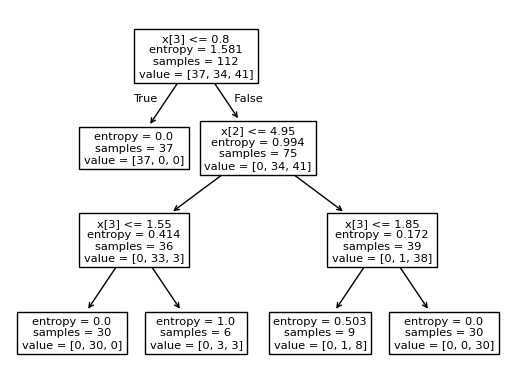

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.datasets import load_iris
from sklearn import tree
iris = load_iris()
X = iris.data
y = iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)
clf = DecisionTreeClassifier(criterion="entropy",min_impurity_decrease=0.002,random_state=0,min_samples_leaf=5)
clf.fit(X_train, y_train)
tree.plot_tree(clf)

Ejercicio 1

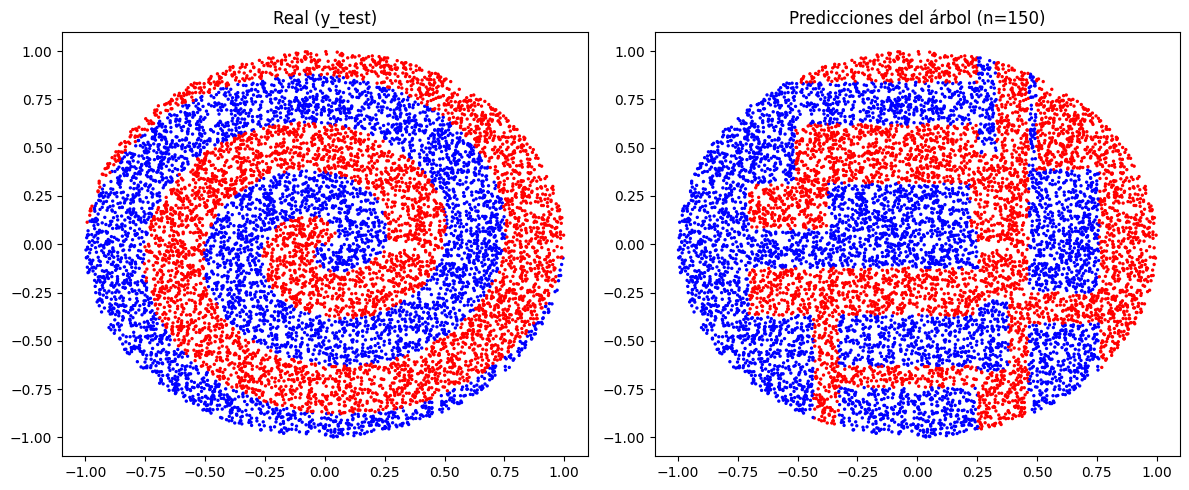

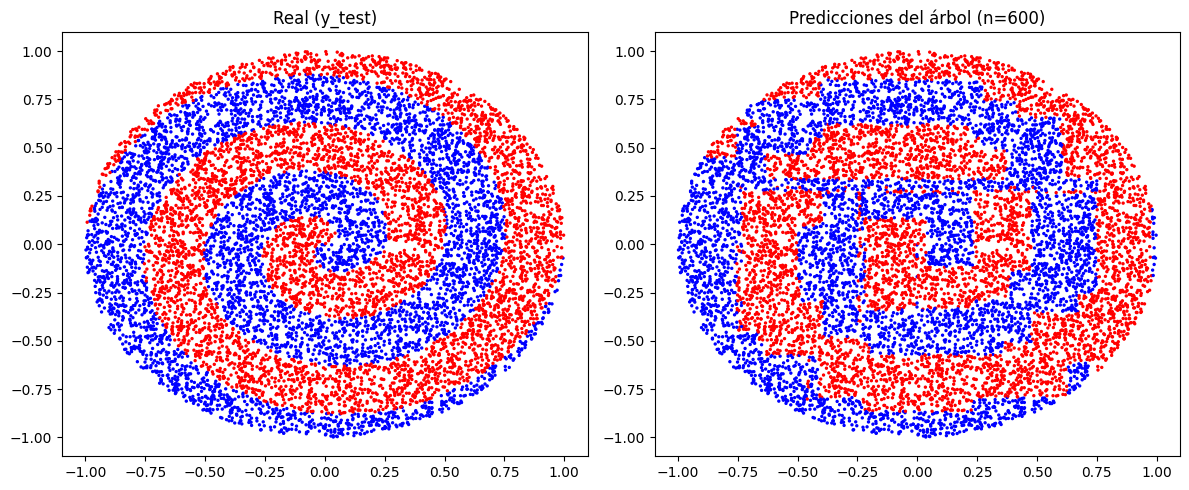

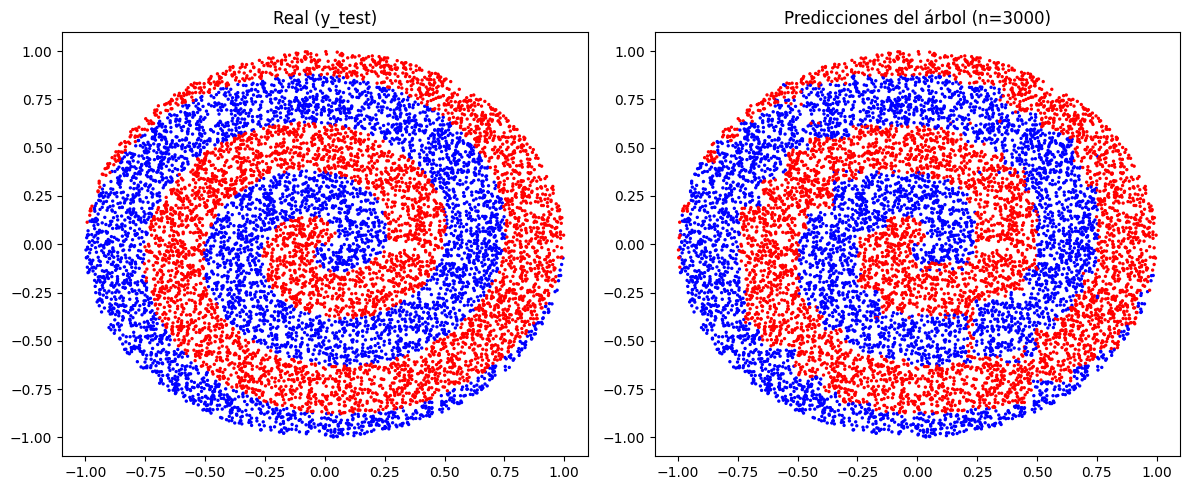

In [ ]:
# Datos de test
X_test, y_test = espirales(10000)

tamanos_entrenamiento = [150, 600, 3000]

for n in tamanos_entrenamiento:
    # Datos de entrenamiento
    X_train, y_train = espirales(n)

    # Modelo
    clf = DecisionTreeClassifier(criterion="entropy", random_state=0)
    clf.fit(X_train, y_train)

    # Predicciones
    predicciones = clf.predict(X_test)

    # Gráficas
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap="bwr", s=2)
    axes[0].set_title("Real (y_test)")

    axes[1].scatter(X_test[:, 0], X_test[:, 1], c=predicciones, cmap="bwr", s=2)
    axes[1].set_title(f"Predicciones del árbol (n={n})")

    plt.tight_layout()
    plt.show()


Conclusiones Ejercicio 1: A medida que aumenta el tamaño del conjunto de entrenamiento (de 150 a 3000 puntos), las predicciones del árbol sobre el test se acercan progresivamente a la forma real de las espirales.

Con n=150 el árbol tiene muy pocos ejemplos por región y las predicciones son ruidosas y poco coherentes con la forma de las espirales. Con n=600 se empieza a distinguir la estructura espiral pero con mucho error. Con n=3000 la aproximación es notablemente mejor, aunque sigue siendo una "escalera" que imita la curva. Esto ilustra que aumentar datos ayuda, pero no resuelve la limitación estructural del modelo frente a problemas con fronteras complejas y no alineadas con los ejes.

Ejercicio 2:

In [ ]:
def make_clf():
    """Árbol con parámetros estándar del enunciado."""
    return DecisionTreeClassifier(
        criterion="entropy",
        min_impurity_decrease=0.002,
        random_state=0,
        min_samples_leaf=5
    )


#Generando el entrenamiento

In [ ]:
from sklearn.metrics import accuracy_score

C, d = 0.78, 2
N_REPS = 20
N_TEST = 10000
N_TRAINS = [125, 250, 500, 1000, 2000, 4000]
generators = {"Diagonal": diagonales, "Paralelas": paralelas}

np.random.seed(42)

# Conjuntos de test fijos
X_tests = {name: gen(d, C, N_TEST) for name, gen in generators.items()}

# Experimento

results = {name: {n: {"train_err": [], "test_err": [], "n_nodes": []}
                  for n in N_TRAINS}
           for name in generators}

for name, gen in generators.items():
    X_test, y_test = X_tests[name]
    for n in N_TRAINS:
        for _ in range(N_REPS):
            X_tr, y_tr = gen(d, C, n)
            clf = make_clf()
            clf.fit(X_tr, y_tr)
            results[name][n]["train_err"].append(1 - accuracy_score(y_tr,    clf.predict(X_tr)))
            results[name][n]["test_err" ].append(1 - accuracy_score(y_test,  clf.predict(X_test)))
            results[name][n]["n_nodes"  ].append(clf.tree_.node_count)

means = {name: {n: {k: np.mean(v) for k, v in res.items()}
                for n, res in nr.items()}
         for name, nr in results.items()}


#Mostrando los resultados generados:

In [ ]:
print(f"{'Generador':<15} | {'N_Train':<8} | {'Train Error':<12} | {'Test Error':<12} | {'diff'} | {'Nodos'}")
print("-" * 70)

for nombre_gen, n_dict in means.items():
    for n_train in sorted(n_dict.keys()):
        metricas = n_dict[n_train]
        train_err = f"{metricas['train_err']:.4f}"
        test_err  = f"{metricas['test_err']:.4f}"
        diff      = f"{abs(metricas['train_err'] - metricas['test_err']):.4f}"
        nodos     = f"{metricas['n_nodes']:.1f}"

        print(f"{nombre_gen:<15} | {n_train:<8} | {train_err:<12} | {test_err:<12} | {diff} | {nodos}")


Generador       | N_Train  | Train Error  | Test Error   | diff | Nodos
----------------------------------------------------------------------
Diagonal        | 125      | 0.0726       | 0.1392       | 0.0666 | 19.2
Diagonal        | 250      | 0.0714       | 0.1355       | 0.0641 | 33.0
Diagonal        | 500      | 0.0647       | 0.1304       | 0.0657 | 57.4
Diagonal        | 1000     | 0.0786       | 0.1243       | 0.0457 | 70.8
Diagonal        | 2000     | 0.0903       | 0.1119       | 0.0216 | 48.3
Diagonal        | 4000     | 0.0970       | 0.1110       | 0.0139 | 42.1
Paralelas       | 125      | 0.0681       | 0.1252       | 0.0571 | 16.5
Paralelas       | 250      | 0.0666       | 0.1296       | 0.0630 | 28.4
Paralelas       | 500      | 0.0704       | 0.1278       | 0.0574 | 53.5
Paralelas       | 1000     | 0.0809       | 0.1192       | 0.0382 | 52.8
Paralelas       | 2000     | 0.0918       | 0.1045       | 0.0126 | 25.7
Paralelas       | 4000     | 0.0994       | 0.1011    

Acá se puede notar que a medida que vamos aumentando el tamaño de la muestra (N TRAIN) nuestro modelo efectivamente generaliza mejor, pero a costa de aumentar el error en nuestros datos de entrenamiento. Esto ocurre ya que no generamos el árbol completo, sino que lo podamos para que no crezca indefinidamente (se puede ver en la función make_clf que tenemos parámetros que interrumpen el crecimiento como min_impurity_decrease y min_samples_leaf).

Además, vemos como el árbol generado tiene una cantidad mayor de nodos cuando se lo entrena con 1000 puntos. Esto ocurre ya que este es el punto donde el ruido y el patrón general se mezclan, y entonces el árbol no puede todavía dividir aquellos datos que son ruido y aquellos que estan correctamente clasificados. Dicho de otra forma, como la muestra total no es lo suficientemente grande, la entropía cambia de manera significativa y el árbol todavía no es capaz de descartar esos ejemplos que son ruido.

Otro dato más interesante que podemos ver es que al modelo le cuesta más el problema de las diagonales que el de las paralelas, probablemente porque el patrón diagonal es más difícil de representar en contraparte con la línea vertical que supone el problema de las paralelas.

Figura 1: Predicciones obtenidas para cada conjunto de entrenamiento.

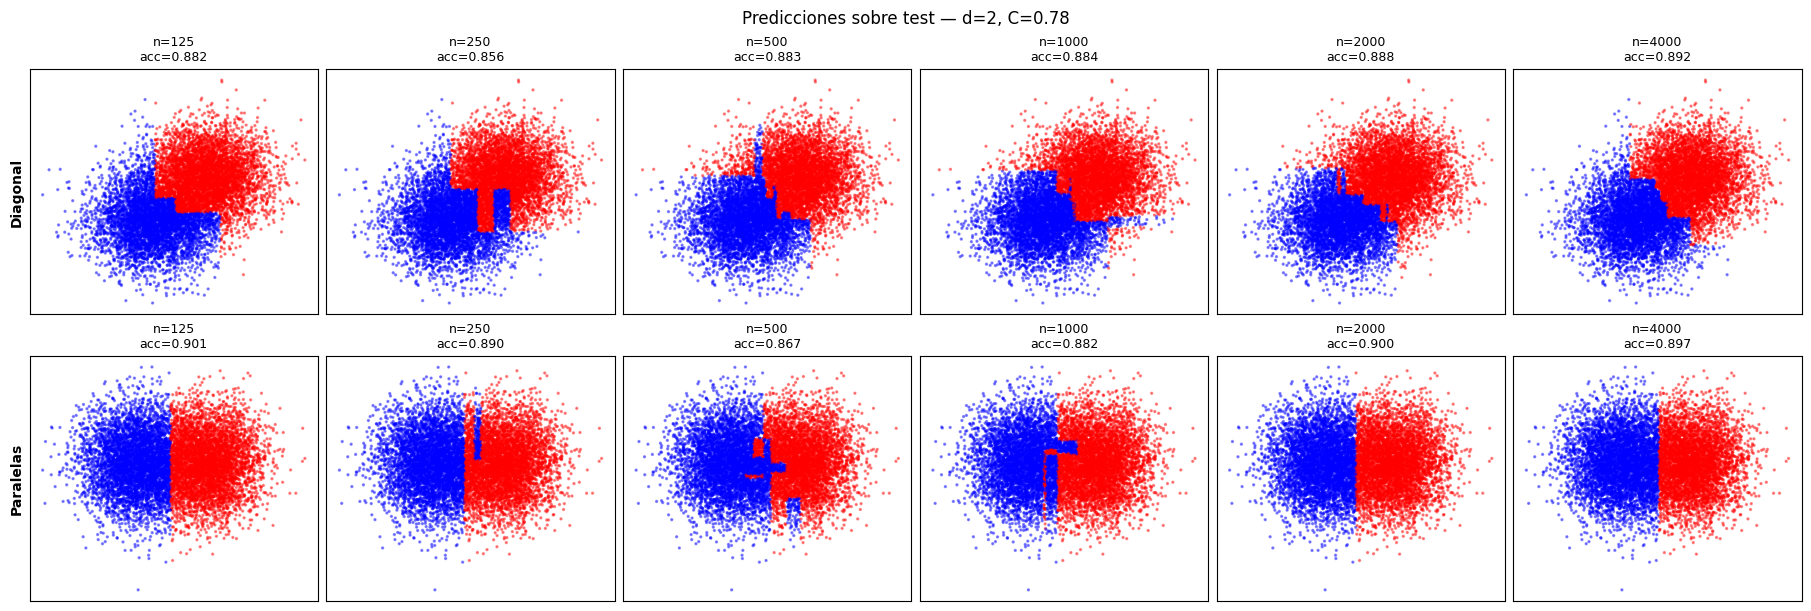

In [ ]:
fig, axes = plt.subplots(2, len(N_TRAINS), figsize=(18, 6), constrained_layout=True)
fig.suptitle("Predicciones sobre test — d=2, C=0.78", fontsize=12)

for row, (name, gen) in enumerate(generators.items()):
    X_test, y_test = X_tests[name]
    for col, n in enumerate(N_TRAINS):
        np.random.seed(0)
        X_tr, y_tr = gen(d, C, n)
        clf = make_clf(); clf.fit(X_tr, y_tr)
        y_pred = clf.predict(X_test)
        ax = axes[row, col]
        ax.scatter(X_test[:, 0], X_test[:, 1], c=y_pred, cmap="bwr",
                   s=2, alpha=0.4, rasterized=True)
        ax.set_title(f"n={n}\nacc={accuracy_score(y_test, y_pred):.3f}", fontsize=9)
        ax.set_xticks([]); ax.set_yticks([])
        if col == 0:
            ax.set_ylabel(name, fontsize=10, fontweight="bold")

plt.show()


Acá vemos como el sistema va aprendiendo más el patrón subyacente a medida que la cantidad de nuestra muestra aumenta. Un caso interesante es el n=125 de Paralelas, el cual tiene un accuracy muy alto. Esto ocurrió ya que la muestra fue significativa de la distribución esperada y pudo generalizar el patrón correctamente.

Figura 2: error y nodos vs n

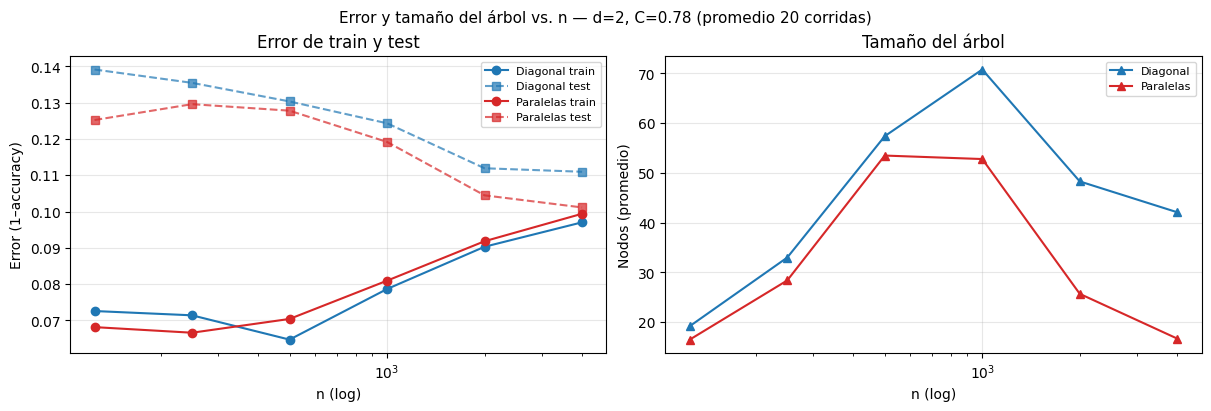

In [ ]:
colors = {"Diagonal": "#1f77b4", "Paralelas": "#d62728"}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
fig.suptitle("Error y tamaño del árbol vs. n — d=2, C=0.78 (promedio 20 corridas)", fontsize=11)

for name in generators:
    c = colors[name]
    tr = [means[name][n]["train_err"] for n in N_TRAINS]
    te = [means[name][n]["test_err"]  for n in N_TRAINS]
    nd = [means[name][n]["n_nodes"]   for n in N_TRAINS]
    ax1.plot(N_TRAINS, tr, "o-",  color=c, label=f"{name} train")
    ax1.plot(N_TRAINS, te, "s--", color=c, alpha=0.7, label=f"{name} test")
    ax2.plot(N_TRAINS, nd, "^-",  color=c, label=name)

for ax, ylabel, title in [
    (ax1, "Error (1–accuracy)", "Error de train y test"),
    (ax2, "Nodos (promedio)",   "Tamaño del árbol"),
]:
    ax.set_xscale("log"); ax.set_xlabel("n (log)"); ax.set_ylabel(ylabel)
    ax.set_title(title); ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

plt.show()

Conclusiones Ejercicio 2

Observando las predicciones sobre test: con conjuntos de entrenamiento chicos (n=125, 250) las fronteras son irregulares y ruidosas, el árbol se ajusta al ruido de los pocos datos disponibles. A medida que n crece, las fronteras se vuelven más suaves y representativas del patrón real. Para el problema paralelo esto ocurre más rápido, ya que la frontera óptima es perpendicular a un eje, que es exactamente el tipo de corte que un árbol puede hacer de forma natural y eficiente.

Sobre el error de train y test: el error de entrenamiento es siempre bajo (el árbol memoriza los datos), mientras que el error de test decrece a medida que n crece. El sobreajuste (que se puede interpretar como la diferencia entre el error de entrenamiento con el error de test) es grande para n pequeño y se reduce con más datos. Esto es el comportamiento clásico de sobreajuste: con pocos datos el árbol aprende el ruido, no el patrón.

Sobre el número de nodos: el árbol crece con n porque tiene más ejemplos para generar cortes informativos. Sin embargo, no crece indefinidamente: los parámetros min_impurity_decrease y min_samples_leaf actúan como regularización y limitan el tamaño. El pico de nodos que se observa en valores intermedios de n se debe a que en ese rango el árbol tiene suficientes datos para hacer muchos cortes pero aún no puede distinguir bien el ruido del patrón, generando ramas innecesarias. Con n muy grande el árbol puede ser más compacto porque los patrones son más claros y consistentes en el espacio de features.

Diagonal vs. Paralelo: el problema paralelo tiene errores de test menores para todo n. Esto ocurre porque su frontera óptima es perpendicular al primer eje, algo que un árbol de decisión puede representar con un solo corte. El diagonal, en cambio, tiene una frontera oblicua que requiere muchos cortes escalonados para ser aproximada, lo que demanda más datos para generalizarse bien.

Ejercicio 3

Error de Bayes diagonal C=1.0: 15.50%  (referencia: 15.86%)


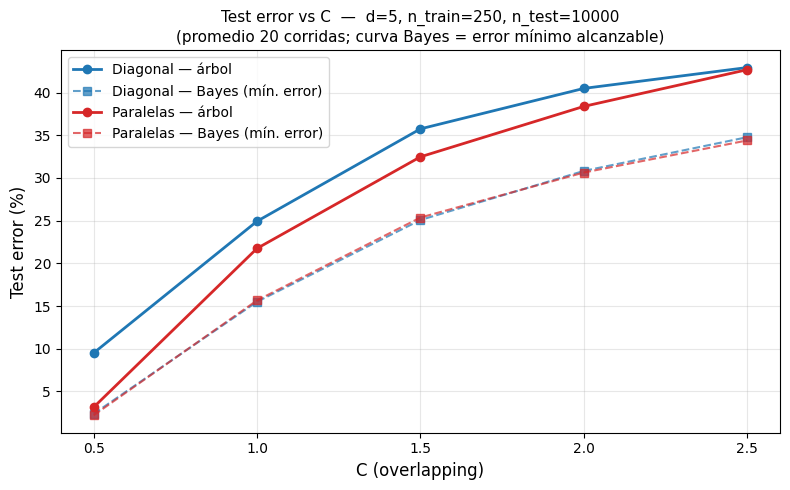

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from scipy.stats import multivariate_normal
import numpy as np
import matplotlib.pyplot as plt

# Parámetros
d        = 5
N_TRAIN  = 250
N_TEST   = 10_000
N_REPS   = 20
C_VALUES = [0.5, 1.0, 1.5, 2.0, 2.5]

np.random.seed(42)

def make_clf():
    return DecisionTreeClassifier(
        criterion="entropy",
        min_impurity_decrease=0.002,
        min_samples_leaf=5,
    )

# Clasificador de Bayes: calcula P(clase | x) y asigna la más probable
def bayes_error(C, d, gen_fn, n_test=10_000):
    """
    Mide el error del clasificador de Bayes directamente sobre el conjunto
    de test. Para cada punto x, predice la clase con mayor verosimilitud
    p(x | clase). Como los priors son iguales (n/2 de cada clase), esto
    equivale al clasificador de mínimo error (Bayes óptimo).
    """
    X_test, y_test = gen_fn(d, C, n_test)

    # Medias de cada clase (dependen del generador)
    if gen_fn == diagonales:
        mu0 = -np.ones(d)
        mu1 =  np.ones(d)
        std = C * np.sqrt(d)
        cov = np.diag(np.full(d, std**2))
    else:  # paralelas
        mu0 = np.zeros(d); mu0[0] = -1
        mu1 = np.zeros(d); mu1[0] =  1
        cov = C**2 * np.eye(d)

    rv0 = multivariate_normal(mu0, cov)
    rv1 = multivariate_normal(mu1, cov)

    y_bayes = (rv1.pdf(X_test) > rv0.pdf(X_test)).astype(int)
    return np.mean(y_bayes != y_test)

# Experimento principal
generators = {"Diagonal": diagonales, "Paralelas": paralelas}

results  = {name: [] for name in generators}
bayes_errors = {name: [] for name in generators}

for C in C_VALUES:
    for name, gen in generators.items():

        # Un solo conjunto de test por valor de C
        X_test, y_test = gen(d, C, N_TEST)

        # 20 entrenamientos distintos, mismo test
        errors = []
        for _ in range(N_REPS):
            X_tr, y_tr = gen(d, C, N_TRAIN)
            clf = make_clf()
            clf.fit(X_tr, y_tr)
            errors.append(1 - accuracy_score(y_test, clf.predict(X_test)))

        results[name].append(np.mean(errors))

        # Error de Bayes (Ejercicio 3.1)
        bayes_errors[name].append(bayes_error(C, d, gen))

# Verificación con valor de referencia de la cátedra
idx_c1 = C_VALUES.index(1.0)
ref = bayes_errors["Diagonal"][idx_c1]
print(f"Error de Bayes diagonal C=1.0: {ref*100:.2f}%  (referencia: 15.86%)")

# Gráfica
fig, ax = plt.subplots(figsize=(8, 5))

colors = {"Diagonal": "#1f77b4", "Paralelas": "#d62728"}

for name in generators:
    c = colors[name]
    ax.plot(C_VALUES, [e * 100 for e in results[name]],
            "o-", color=c, linewidth=2, label=f"{name} — árbol")
    ax.plot(C_VALUES, [e * 100 for e in bayes_errors[name]],
            "s--", color=c, linewidth=1.5, alpha=0.7,
            label=f"{name} — Bayes (mín. error)")

ax.set_xlabel("C (overlapping)", fontsize=12)
ax.set_ylabel("Test error (%)", fontsize=12)
ax.set_title("Test error vs C  —  d=5, n_train=250, n_test=10000\n(promedio 20 corridas; curva Bayes = error mínimo alcanzable)",
             fontsize=11)
ax.set_xticks(C_VALUES)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Para el ejercicio 3 se generaron datasets con d=5, n=250 para entrenamiento y n=10000 para test, variando C de 0.5 a 2.5 en pasos de 0.5. Para cada valor de C se creó un solo conjunto de test y 20 conjuntos de entrenamiento distintos, se entrenó un árbol en cada uno y se promediaron los errores sobre ese mismo test. Esto se realizó tanto para el problema diagonal como para el paralelo.

A medida que C crece, el solapamiento entre las clases aumenta y todos los errores suben, tanto para el árbol como para el clasificador de Bayes. Esto es esperable: con mayor C las distribuciones se mezclan más y ningún clasificador puede evitar errores.

La curva de Bayes representa el error mínimo alcanzable para cada valor de C. La brecha entre el árbol y Bayes muestra cuánto se aleja el modelo del óptimo teórico. Esta brecha es mayor en el problema diagonal, especialmente para C alto, porque la frontera óptima es un hiperplano oblicuo y el árbol necesita muchos cortes escalonados para aproximarla con solo 250 puntos de entrenamiento.

El problema paralelo tiene errores de árbol muy cercanos al error de Bayes para todo C, confirmando que cuando la frontera óptima coincide con el tipo de corte que el árbol puede hacer (perpendicular a un eje), el modelo es casi óptimo. En el diagonal, en cambio, el árbol paga un costo sistemático por su incapacidad estructural de hacer cortes oblicuos.

En la gráfica se pueden ver las 4 curvas juntas: el error del árbol y el error de Bayes para cada problema. Se observa que a valores bajos de C el solapamiento entre clases es chico y todos los errores son bajos, mientras que a medida que C crece el solapamiento aumenta y los errores suben en todos los casos. La brecha entre el árbol y la curva de Bayes muestra cuánto se aleja el árbol del clasificador óptimo, especialmente para C alto donde el problema se vuelve más difícil. El problema paralelo resulta más fácil de modelar que el diagonal porque la frontera óptima es perpendicular a un eje, que es exactamente el tipo de corte que un árbol de decisión puede hacer naturalmente.

Ejercicio 4

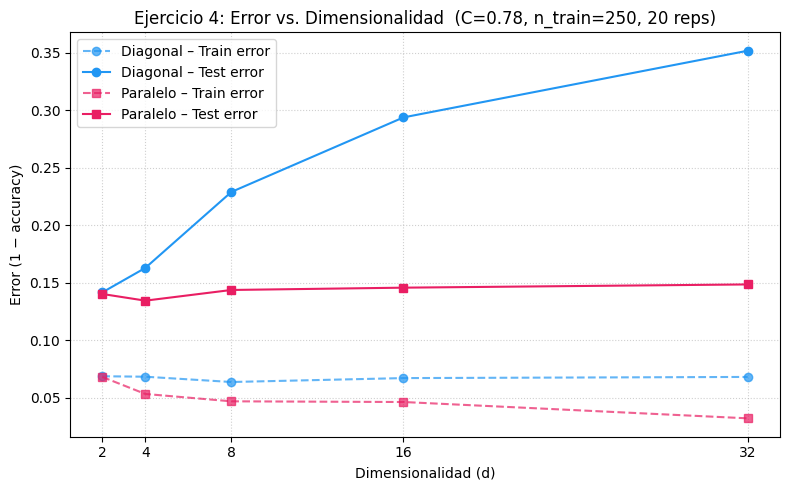

In [ ]:
# Parámetros
np.random.seed(42)
C        = 0.78
N_TRAIN  = 250
N_TEST   = 10000
N_REPS   = 20
D_VALUES = [2, 4, 8, 16, 32]

TREE_PARAMS = dict(
    criterion="entropy",
    min_impurity_decrease=0.002,
    random_state=0,
    min_samples_leaf=5,
)

# Experimento
results = {
    "diagonal": {"train_err": [], "test_err": []},
    "paralelo": {"train_err": [], "test_err": []},
}
generators = {"diagonal": diagonales, "paralelo": paralelas}

for d in D_VALUES:
    for name, gen in generators.items():
        X_test, y_test = gen(d, C, N_TEST)
        train_errors, test_errors = [], []
        for _ in range(N_REPS):
            X_train, y_train = gen(d, C, N_TRAIN)
            clf = DecisionTreeClassifier(**TREE_PARAMS)
            clf.fit(X_train, y_train)
            train_errors.append(1 - clf.score(X_train, y_train))
            test_errors.append(1 - clf.score(X_test, y_test))
        results[name]["train_err"].append(np.mean(train_errors))
        results[name]["test_err"].append(np.mean(test_errors))

# Gráfica
fig, ax = plt.subplots(figsize=(8, 5))
colors  = {"diagonal": "#2196F3", "paralelo": "#E91E63"}
markers = {"diagonal": "o", "paralelo": "s"}

for name in ["diagonal", "paralelo"]:
    ax.plot(D_VALUES, results[name]["train_err"],
            linestyle="--", marker=markers[name], color=colors[name],
            alpha=0.7, label=f"{name.capitalize()} – Train error")
    ax.plot(D_VALUES, results[name]["test_err"],
            linestyle="-",  marker=markers[name], color=colors[name],
            label=f"{name.capitalize()} – Test error")

ax.set_xlabel("Dimensionalidad (d)")
ax.set_ylabel("Error (1 − accuracy)")
ax.set_title(f"Error vs. Dimensionalidad  (C={C}, n_train={N_TRAIN}, {N_REPS} reps)")
ax.set_xticks(D_VALUES)
ax.legend()
ax.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()


El experimento muestra que la dimensionalidad afecta de forma muy distinta a cada problema.

En el problema paralelo el test error se mantiene prácticamente estable al aumentar d. Esto se explica porque la separación entre clases ocurre únicamente en la primera dimensión; las dimensiones adicionales son irrelevantes para la clasificación y el árbol las ignora naturalmente al elegir el mejor corte en cada nodo.

En el problema diagonal el test error crece de forma considerable con d. Hay dos razones combinadas: por un lado, la dispersión de las gaussianas crece con d (σ = C·√d), lo que aumenta el solapamiento entre clases en cada dimensión. Por otro lado, la frontera óptima es una hiperplana oblicua que involucra todas las coordenadas simultáneamente; para aproximarla el árbol necesita muchos nodos, pero con solo 250 puntos de entrenamiento distribuidos en un espacio de dimensión creciente (maldición de la dimensionalidad), cada región del espacio tiene cada vez menos ejemplos y los cortes son menos confiables.

En ambos casos el train error permanece bajo independientemente de d, lo que confirma que el árbol memoriza los datos de entrenamiento sin dificultad. La diferencia está en la capacidad de generalización, que se deteriora con d solo cuando la estructura del problema lo exige.

Ejercicio 5:

In [ ]:
data = [(8.781019003471183249e-01,1.855279616375934415e-01,0.000000000000000000e+00),
(9.209004548704728954e-01,9.465658637675279374e-01,0.000000000000000000e+00),
(8.745080903846549347e-01,1.157427629133893632e-01,0.000000000000000000e+00),
(1.937316623655526149e-01,3.417371975176514143e-01,0.000000000000000000e+00),
(4.957909002612719274e-01,8.983712328050620366e-01,0.000000000000000000e+00),
(6.458619199523063514e-03,2.274114670050211284e-01,0.000000000000000000e+00),
(7.936549524061070615e-01,4.142867178061111488e-01,0.000000000000000000e+00),
(8.381440312009591498e-02,3.920956355907274649e-01,0.000000000000000000e+00),
(3.395712267303314658e-01,2.230246673762226184e-02,0.000000000000000000e+00),
(8.904383159378265189e-01,2.386968267583733372e-02,0.000000000000000000e+00),
(8.358203215531584407e-01,4.595984155115756531e-01,0.000000000000000000e+00),
(4.043169293821835542e-02,8.129903033846213045e-01,0.000000000000000000e+00),
(7.763536531249806139e-01,7.171288217547389099e-01,0.000000000000000000e+00),
(6.541718021012443707e-02,6.287901391555317243e-01,0.000000000000000000e+00),
(9.861796493550943898e-01,7.713139531688106842e-01,0.000000000000000000e+00),
(2.140802974700967143e-01,8.587356713928673280e-02,0.000000000000000000e+00),
(9.736313987689836358e-01,7.404913092875106129e-01,0.000000000000000000e+00),
(9.787673429827805638e-01,7.861714601935549940e-01,0.000000000000000000e+00),
(1.335567559064544385e-01,1.193902100692202373e-01,0.000000000000000000e+00),
(2.219083095655537408e-01,6.259010523601397091e-01,0.000000000000000000e+00),
(7.006533362407514343e-01,7.696513477779343138e-01,0.000000000000000000e+00),
(4.052123197819564870e-01,3.510126146310701412e-01,0.000000000000000000e+00),
(9.012123722613640808e-01,9.213922276612940276e-02,0.000000000000000000e+00),
(2.052023792229715760e-01,3.242792819276280047e-01,0.000000000000000000e+00),
(8.075554275470144816e-01,4.630955765554676251e-01,0.000000000000000000e+00),
(8.540483064834327731e-01,9.163807994273224233e-01,0.000000000000000000e+00),
(2.818530087214202728e-01,3.119958527285674466e-01,0.000000000000000000e+00),
(1.177663180603282234e-01,1.414288401004500928e-01,0.000000000000000000e+00),
(8.154234406971880844e-01,2.540097167836229408e-01,0.000000000000000000e+00),
(8.327331759135803146e-02,8.817309752916396848e-01,0.000000000000000000e+00),
(3.027730078824657500e-01,8.116587334558181821e-01,0.000000000000000000e+00),
(6.347664548758880088e-02,6.782493558995675853e-01,0.000000000000000000e+00),
(7.784052802046503849e-02,4.449196230348556602e-01,0.000000000000000000e+00),
(3.789818174644361548e-01,2.552485001522085684e-01,0.000000000000000000e+00),
(2.948088061012401617e-01,2.284053005812004544e-01,0.000000000000000000e+00),
(7.121702624293538841e-01,1.376628254357448178e-01,0.000000000000000000e+00),
(6.201676781767905267e-01,1.591878066892503663e-01,0.000000000000000000e+00),
(9.666593957624950439e-01,5.918037219262083370e-01,0.000000000000000000e+00),
(5.134659985071183819e-01,6.287977210302198028e-01,0.000000000000000000e+00),
(4.102649885032760846e-01,7.438910928843124326e-01,0.000000000000000000e+00),
(4.677809205511288537e-01,6.511408194275905004e-01,0.000000000000000000e+00),
(1.413606538345648644e-01,7.479262076525264868e-01,0.000000000000000000e+00),
(5.078601519796885899e-01,1.762420220120324288e-01,0.000000000000000000e+00),
(3.973141169726041033e-01,5.561414036353202750e-01,0.000000000000000000e+00),
(2.250352844165759425e-02,9.058694694403378600e-01,0.000000000000000000e+00),
(5.429289898582533302e-01,2.989676991206282608e-01,0.000000000000000000e+00),
(6.448290533126466162e-01,2.186626062441143770e-02,0.000000000000000000e+00),
(1.737000017076151259e-01,6.021941587530623696e-01,0.000000000000000000e+00),
(1.320561882675886922e-01,9.701462453799668539e-01,0.000000000000000000e+00),
(9.096554804179622922e-01,3.937550138327237104e-01,0.000000000000000000e+00),
(-8.781019003471183249e-01,-1.855279616375934415e-01,0.000000000000000000e+00),
(-9.209004548704728954e-01,-9.465658637675279374e-01,0.000000000000000000e+00),
(-8.745080903846549347e-01,-1.157427629133893632e-01,0.000000000000000000e+00),
(-1.937316623655526149e-01,-3.417371975176514143e-01,0.000000000000000000e+00),
(-4.957909002612719274e-01,-8.983712328050620366e-01,0.000000000000000000e+00),
(-6.458619199523063514e-03,-2.274114670050211284e-01,0.000000000000000000e+00),
(-7.936549524061070615e-01,-4.142867178061111488e-01,0.000000000000000000e+00),
(-8.381440312009591498e-02,-3.920956355907274649e-01,0.000000000000000000e+00),
(-3.395712267303314658e-01,-2.230246673762226184e-02,0.000000000000000000e+00),
(-8.904383159378265189e-01,-2.386968267583733372e-02,0.000000000000000000e+00),
(-8.358203215531584407e-01,-4.595984155115756531e-01,0.000000000000000000e+00),
(-4.043169293821835542e-02,-8.129903033846213045e-01,0.000000000000000000e+00),
(-7.763536531249806139e-01,-7.171288217547389099e-01,0.000000000000000000e+00),
(-6.541718021012443707e-02,-6.287901391555317243e-01,0.000000000000000000e+00),
(-9.861796493550943898e-01,-7.713139531688106842e-01,0.000000000000000000e+00),
(-2.140802974700967143e-01,-8.587356713928673280e-02,0.000000000000000000e+00),
(-9.736313987689836358e-01,-7.404913092875106129e-01,0.000000000000000000e+00),
(-9.787673429827805638e-01,-7.861714601935549940e-01,0.000000000000000000e+00),
(-1.335567559064544385e-01,-1.193902100692202373e-01,0.000000000000000000e+00),
(-2.219083095655537408e-01,-6.259010523601397091e-01,0.000000000000000000e+00),
(-7.006533362407514343e-01,-7.696513477779343138e-01,0.000000000000000000e+00),
(-4.052123197819564870e-01,-3.510126146310701412e-01,0.000000000000000000e+00),
(-9.012123722613640808e-01,-9.213922276612940276e-02,0.000000000000000000e+00),
(-2.052023792229715760e-01,-3.242792819276280047e-01,0.000000000000000000e+00),
(-8.075554275470144816e-01,-4.630955765554676251e-01,0.000000000000000000e+00),
(-8.540483064834327731e-01,-9.163807994273224233e-01,0.000000000000000000e+00),
(-2.818530087214202728e-01,-3.119958527285674466e-01,0.000000000000000000e+00),
(-1.177663180603282234e-01,-1.414288401004500928e-01,0.000000000000000000e+00),
(-8.154234406971880844e-01,-2.540097167836229408e-01,0.000000000000000000e+00),
(-8.327331759135803146e-02,-8.817309752916396848e-01,0.000000000000000000e+00),
(-3.027730078824657500e-01,-8.116587334558181821e-01,0.000000000000000000e+00),
(-6.347664548758880088e-02,-6.782493558995675853e-01,0.000000000000000000e+00),
(-7.784052802046503849e-02,-4.449196230348556602e-01,0.000000000000000000e+00),
(-3.789818174644361548e-01,-2.552485001522085684e-01,0.000000000000000000e+00),
(-2.948088061012401617e-01,-2.284053005812004544e-01,0.000000000000000000e+00),
(-7.121702624293538841e-01,-1.376628254357448178e-01,0.000000000000000000e+00),
(-6.201676781767905267e-01,-1.591878066892503663e-01,0.000000000000000000e+00),
(-9.666593957624950439e-01,-5.918037219262083370e-01,0.000000000000000000e+00),
(-5.134659985071183819e-01,-6.287977210302198028e-01,0.000000000000000000e+00),
(-4.102649885032760846e-01,-7.438910928843124326e-01,0.000000000000000000e+00),
(-4.677809205511288537e-01,-6.511408194275905004e-01,0.000000000000000000e+00),
(-1.413606538345648644e-01,-7.479262076525264868e-01,0.000000000000000000e+00),
(-5.078601519796885899e-01,-1.762420220120324288e-01,0.000000000000000000e+00),
(-3.973141169726041033e-01,-5.561414036353202750e-01,0.000000000000000000e+00),
(-2.250352844165759425e-02,-9.058694694403378600e-01,0.000000000000000000e+00),
(-5.429289898582533302e-01,-2.989676991206282608e-01,0.000000000000000000e+00),
(-6.448290533126466162e-01,-2.186626062441143770e-02,0.000000000000000000e+00),
(-1.737000017076151259e-01,-6.021941587530623696e-01,0.000000000000000000e+00),
(-1.320561882675886922e-01,-9.701462453799668539e-01,0.000000000000000000e+00),
(-9.096554804179622922e-01,-3.937550138327237104e-01,0.000000000000000000e+00),
(-8.781019003471183249e-01,1.855279616375934415e-01,1.000000000000000000e+00),
(-9.209004548704728954e-01,9.465658637675279374e-01,1.000000000000000000e+00),
(-8.745080903846549347e-01,1.157427629133893632e-01,1.000000000000000000e+00),
(-1.937316623655526149e-01,3.417371975176514143e-01,1.000000000000000000e+00),
(-4.957909002612719274e-01,8.983712328050620366e-01,1.000000000000000000e+00),
(-6.458619199523063514e-03,2.274114670050211284e-01,1.000000000000000000e+00),
(-7.936549524061070615e-01,4.142867178061111488e-01,1.000000000000000000e+00),
(-8.381440312009591498e-02,3.920956355907274649e-01,1.000000000000000000e+00),
(-3.395712267303314658e-01,2.230246673762226184e-02,1.000000000000000000e+00),
(-8.904383159378265189e-01,2.386968267583733372e-02,1.000000000000000000e+00),
(-8.358203215531584407e-01,4.595984155115756531e-01,1.000000000000000000e+00),
(-4.043169293821835542e-02,8.129903033846213045e-01,1.000000000000000000e+00),
(-7.763536531249806139e-01,7.171288217547389099e-01,1.000000000000000000e+00),
(-6.541718021012443707e-02,6.287901391555317243e-01,1.000000000000000000e+00),
(-9.861796493550943898e-01,7.713139531688106842e-01,1.000000000000000000e+00),
(-2.140802974700967143e-01,8.587356713928673280e-02,1.000000000000000000e+00),
(-9.736313987689836358e-01,7.404913092875106129e-01,1.000000000000000000e+00),
(-9.787673429827805638e-01,7.861714601935549940e-01,1.000000000000000000e+00),
(-1.335567559064544385e-01,1.193902100692202373e-01,1.000000000000000000e+00),
(-2.219083095655537408e-01,6.259010523601397091e-01,1.000000000000000000e+00),
(-7.006533362407514343e-01,7.696513477779343138e-01,1.000000000000000000e+00),
(-4.052123197819564870e-01,3.510126146310701412e-01,1.000000000000000000e+00),
(-9.012123722613640808e-01,9.213922276612940276e-02,1.000000000000000000e+00),
(-2.052023792229715760e-01,3.242792819276280047e-01,1.000000000000000000e+00),
(-8.075554275470144816e-01,4.630955765554676251e-01,1.000000000000000000e+00),
(-8.540483064834327731e-01,9.163807994273224233e-01,1.000000000000000000e+00),
(-2.818530087214202728e-01,3.119958527285674466e-01,1.000000000000000000e+00),
(-1.177663180603282234e-01,1.414288401004500928e-01,1.000000000000000000e+00),
(-8.154234406971880844e-01,2.540097167836229408e-01,1.000000000000000000e+00),
(-8.327331759135803146e-02,8.817309752916396848e-01,1.000000000000000000e+00),
(-3.027730078824657500e-01,8.116587334558181821e-01,1.000000000000000000e+00),
(-6.347664548758880088e-02,6.782493558995675853e-01,1.000000000000000000e+00),
(-7.784052802046503849e-02,4.449196230348556602e-01,1.000000000000000000e+00),
(-3.789818174644361548e-01,2.552485001522085684e-01,1.000000000000000000e+00),
(-2.948088061012401617e-01,2.284053005812004544e-01,1.000000000000000000e+00),
(-7.121702624293538841e-01,1.376628254357448178e-01,1.000000000000000000e+00),
(-6.201676781767905267e-01,1.591878066892503663e-01,1.000000000000000000e+00),
(-9.666593957624950439e-01,5.918037219262083370e-01,1.000000000000000000e+00),
(-5.134659985071183819e-01,6.287977210302198028e-01,1.000000000000000000e+00),
(-4.102649885032760846e-01,7.438910928843124326e-01,1.000000000000000000e+00),
(-4.677809205511288537e-01,6.511408194275905004e-01,1.000000000000000000e+00),
(-1.413606538345648644e-01,7.479262076525264868e-01,1.000000000000000000e+00),
(-5.078601519796885899e-01,1.762420220120324288e-01,1.000000000000000000e+00),
(-3.973141169726041033e-01,5.561414036353202750e-01,1.000000000000000000e+00),
(-2.250352844165759425e-02,9.058694694403378600e-01,1.000000000000000000e+00),
(-5.429289898582533302e-01,2.989676991206282608e-01,1.000000000000000000e+00),
(-6.448290533126466162e-01,2.186626062441143770e-02,1.000000000000000000e+00),
(-1.737000017076151259e-01,6.021941587530623696e-01,1.000000000000000000e+00),
(-1.320561882675886922e-01,9.701462453799668539e-01,1.000000000000000000e+00),
(-9.096554804179622922e-01,3.937550138327237104e-01,1.000000000000000000e+00),
(8.781019003471183249e-01,-1.855279616375934415e-01,1.000000000000000000e+00),
(9.209004548704728954e-01,-9.465658637675279374e-01,1.000000000000000000e+00),
(8.745080903846549347e-01,-1.157427629133893632e-01,1.000000000000000000e+00),
(1.937316623655526149e-01,-3.417371975176514143e-01,1.000000000000000000e+00),
(4.957909002612719274e-01,-8.983712328050620366e-01,1.000000000000000000e+00),
(6.458619199523063514e-03,-2.274114670050211284e-01,1.000000000000000000e+00),
(7.936549524061070615e-01,-4.142867178061111488e-01,1.000000000000000000e+00),
(8.381440312009591498e-02,-3.920956355907274649e-01,1.000000000000000000e+00),
(3.395712267303314658e-01,-2.230246673762226184e-02,1.000000000000000000e+00),
(8.904383159378265189e-01,-2.386968267583733372e-02,1.000000000000000000e+00),
(8.358203215531584407e-01,-4.595984155115756531e-01,1.000000000000000000e+00),
(4.043169293821835542e-02,-8.129903033846213045e-01,1.000000000000000000e+00),
(7.763536531249806139e-01,-7.171288217547389099e-01,1.000000000000000000e+00),
(6.541718021012443707e-02,-6.287901391555317243e-01,1.000000000000000000e+00),
(9.861796493550943898e-01,-7.713139531688106842e-01,1.000000000000000000e+00),
(2.140802974700967143e-01,-8.587356713928673280e-02,1.000000000000000000e+00),
(9.736313987689836358e-01,-7.404913092875106129e-01,1.000000000000000000e+00),
(9.787673429827805638e-01,-7.861714601935549940e-01,1.000000000000000000e+00),
(1.335567559064544385e-01,-1.193902100692202373e-01,1.000000000000000000e+00),
(2.219083095655537408e-01,-6.259010523601397091e-01,1.000000000000000000e+00),
(7.006533362407514343e-01,-7.696513477779343138e-01,1.000000000000000000e+00),
(4.052123197819564870e-01,-3.510126146310701412e-01,1.000000000000000000e+00),
(9.012123722613640808e-01,-9.213922276612940276e-02,1.000000000000000000e+00),
(2.052023792229715760e-01,-3.242792819276280047e-01,1.000000000000000000e+00),
(8.075554275470144816e-01,-4.630955765554676251e-01,1.000000000000000000e+00),
(8.540483064834327731e-01,-9.163807994273224233e-01,1.000000000000000000e+00),
(2.818530087214202728e-01,-3.119958527285674466e-01,1.000000000000000000e+00),
(1.177663180603282234e-01,-1.414288401004500928e-01,1.000000000000000000e+00),
(8.154234406971880844e-01,-2.540097167836229408e-01,1.000000000000000000e+00),
(8.327331759135803146e-02,-8.817309752916396848e-01,1.000000000000000000e+00),
(3.027730078824657500e-01,-8.116587334558181821e-01,1.000000000000000000e+00),
(6.347664548758880088e-02,-6.782493558995675853e-01,1.000000000000000000e+00),
(7.784052802046503849e-02,-4.449196230348556602e-01,1.000000000000000000e+00),
(3.789818174644361548e-01,-2.552485001522085684e-01,1.000000000000000000e+00),
(2.948088061012401617e-01,-2.284053005812004544e-01,1.000000000000000000e+00),
(7.121702624293538841e-01,-1.376628254357448178e-01,1.000000000000000000e+00),
(6.201676781767905267e-01,-1.591878066892503663e-01,1.000000000000000000e+00),
(9.666593957624950439e-01,-5.918037219262083370e-01,1.000000000000000000e+00),
(5.134659985071183819e-01,-6.287977210302198028e-01,1.000000000000000000e+00),
(4.102649885032760846e-01,-7.438910928843124326e-01,1.000000000000000000e+00),
(4.677809205511288537e-01,-6.511408194275905004e-01,1.000000000000000000e+00),
(1.413606538345648644e-01,-7.479262076525264868e-01,1.000000000000000000e+00),
(5.078601519796885899e-01,-1.762420220120324288e-01,1.000000000000000000e+00),
(3.973141169726041033e-01,-5.561414036353202750e-01,1.000000000000000000e+00),
(2.250352844165759425e-02,-9.058694694403378600e-01,1.000000000000000000e+00),
(5.429289898582533302e-01,-2.989676991206282608e-01,1.000000000000000000e+00),
(6.448290533126466162e-01,-2.186626062441143770e-02,1.000000000000000000e+00),
(1.737000017076151259e-01,-6.021941587530623696e-01,1.000000000000000000e+00),
(1.320561882675886922e-01,-9.701462453799668539e-01,1.000000000000000000e+00),
(9.096554804179622922e-01,-3.937550138327237104e-01,1.000000000000000000e+00)]

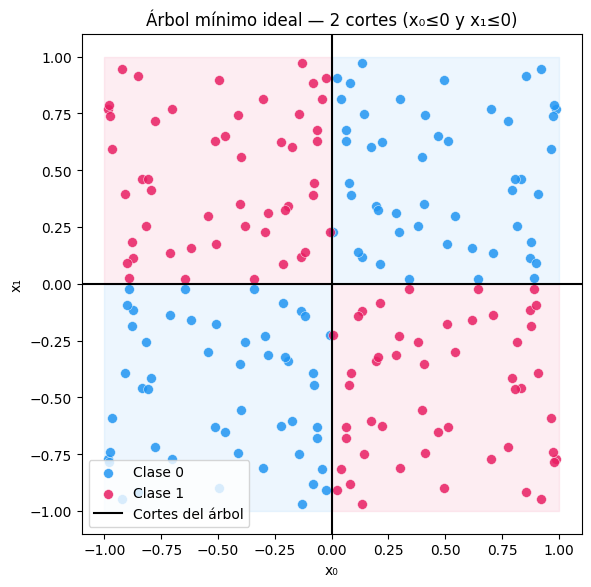

Accuracy: 0.5000
Nodos:    1


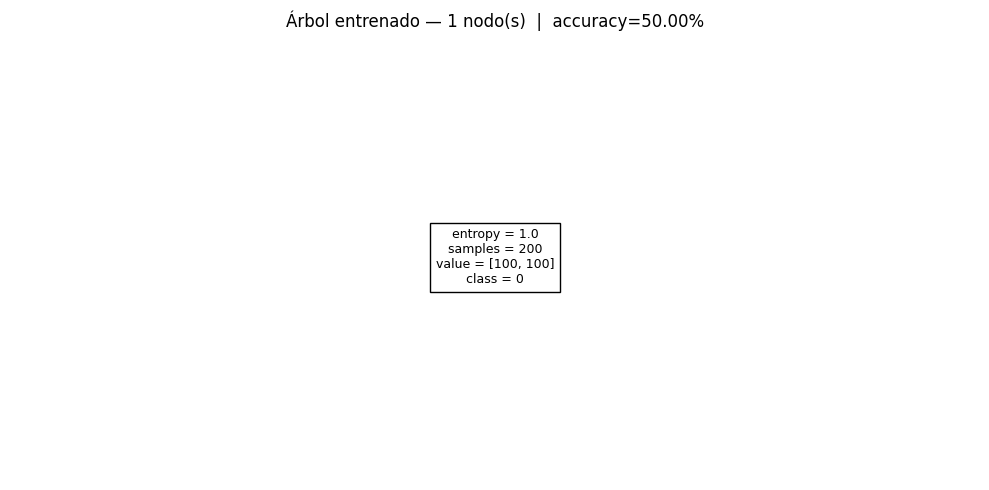

In [ ]:

from sklearn.tree import DecisionTreeClassifier, plot_tree

data_np = np.array(data)
X, y = data_np[:, :2], data_np[:, 2]

TREE_PARAMS = dict(
    criterion="entropy",
    min_impurity_decrease=0.002,
    random_state=0,
    min_samples_leaf=5,
)


# ── Figura 2: árbol mínimo ideal ─────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(6, 6))
for c in [0, 1]:
    mask = y == c
    ax.scatter(X[mask, 0], X[mask, 1], c=colors[c], label=f"Clase {c}",
               edgecolors="white", linewidths=0.4, s=50, alpha=0.85)
ax.axhline(0, color="black", linewidth=1.5, label="Cortes del árbol")
ax.axvline(0, color="black", linewidth=1.5)
ax.fill_between([-1, 0],  0,  1, color="#E91E63", alpha=0.08)
ax.fill_between([ 0,  1], 0,  1, color="#2196F3", alpha=0.08)
ax.fill_between([-1, 0], -1,  0, color="#2196F3", alpha=0.08)
ax.fill_between([ 0,  1], -1, 0, color="#E91E63", alpha=0.08)
ax.set_xlabel("x₀"); ax.set_ylabel("x₁")
ax.set_title("Árbol mínimo ideal — 2 cortes (x₀≤0 y x₁≤0)")
ax.legend(); ax.set_aspect("equal")
ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1)
plt.tight_layout(); plt.show()

# ── Entrenar árbol ───────────────────────────────────────────────────────────
clf = DecisionTreeClassifier(**TREE_PARAMS)
clf.fit(X, y)
print(f"Accuracy: {clf.score(X, y):.4f}")
print(f"Nodos:    {clf.tree_.node_count}")

# ── Figura 3: árbol entrenado ────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))
plot_tree(clf, feature_names=["x₀", "x₁"], class_names=["0", "1"],
          filled=True, ax=ax, fontsize=9)
ax.set_title(f"Árbol entrenado — {clf.tree_.node_count} nodo(s)  |  accuracy={clf.score(X, y):.2%}")
plt.tight_layout(); plt.show()


**Árbol mínimo ideal: mirando el gráfico de los datos**, la estructura XOR queda clara: la clase 0 ocupa los cuadrantes donde x₀ y x₁ tienen el mismo signo (ambos positivos o ambos negativos), y la clase 1 ocupa los cuadrantes donde tienen distinto signo. El árbol más simple que clasifica correctamente todos los puntos tiene 2 nodos de decisión y 4 hojas: el nodo raíz corta en x₀ ≤ 0, y cada rama hace un segundo corte en x₁ ≤ 0. Las 4 hojas corresponden a los 4 cuadrantes.

**Árbol entrenado con parámetros estándar**: con min_impurity_decrease=0.002, el árbol entrenado no aprende nada y predice siempre la misma clase (accuracy 50%). Esto ocurre porque el parámetro exige que cada corte mejore la pureza en al menos 0.002. En XOR, cualquier corte sobre un solo eje (ya sea vertical u horizontal) divide los datos en dos mitades con exactamente la misma proporción de clases —basta ver la simetría del problema: por cada punto en un cuadrante, existe su simétrico en el cuadrante adyacente. El árbol evalúa cada corte de forma greedy y, al no ver mejora inmediata en la impureza, descarta todos los cortes posibles y se queda con un único nodo. El parámetro que normalmente protege del sobreajuste aquí impide cualquier aprendizaje.

**Sin restricciones (min_impurity_decrease=0)**, el árbol logra aprender la estructura XOR pero genera bastantes más nodos de los necesarios, ajustándose a los puntos individuales en lugar de encontrar la solución mínima de 2 cortes. Esto ilustra la tensión clásica entre regularización y capacidad de aprendizaje: demasiada restricción impide aprender, demasiado poca lleva al sobreajuste.

Accuracy: 0.9650
Nodos: 17


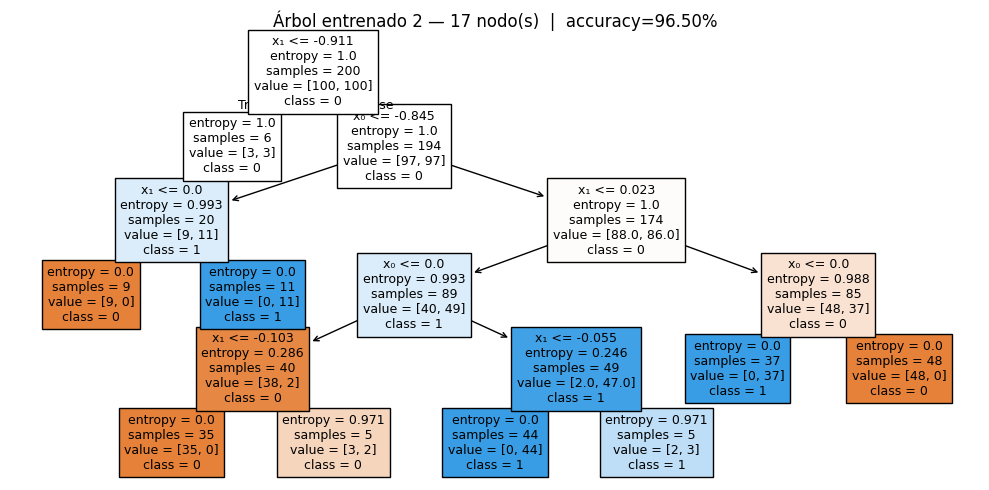

In [ ]:
TREE_PARAMS = dict(
    criterion="entropy",
    random_state=0,
    min_impurity_decrease=0,
    min_samples_leaf=5,
)

clf_libre = DecisionTreeClassifier(**TREE_PARAMS)
clf_libre.fit(X, y)
print(f"Accuracy: {clf_libre.score(X, y):.4f}")
print(f"Nodos: {clf_libre.tree_.node_count}")

fig, ax = plt.subplots(figsize=(10, 5))
plot_tree(clf_libre, feature_names=["x₀", "x₁"], class_names=["0", "1"],
          filled=True, ax=ax, fontsize=9)
ax.set_title(f"Árbol entrenado 2 — {clf_libre.tree_.node_count} nodo(s)  |  accuracy={clf_libre.score(X, y):.2%}")
plt.tight_layout(); plt.show()